# GEA1000 Project Part B: Python analysis (Questions 1 to 5)

This notebook contains the Python analysis behind Part B, Questions 1 to 5, of the GEA1000 project (video games dataset: 1,754 games, where a game is a title on one console).
Anyone should be able to repeat our analysis by following the steps below and running the cells in order.

## How to run it
1. Install Python 3 and these libraries: `pandas` (tables), `numpy` (calculations), `scipy` (statistics) and `matplotlib` (charts), for example with `pip install pandas numpy scipy matplotlib jupyter`.
2. Put `Video_games_dataset.csv` in the folder **above** this notebook (the setup cell reads `../Video_games_dataset.csv`).
3. Open this notebook in Jupyter (`jupyter notebook`) and choose **Kernel > Restart & Run All**. Every question below then runs from top to bottom.
   Run the setup cell first if you run cells one by one, because every later cell uses the table `df` that it creates.

## What each question does
| Question | What the cells do |
|---|---|
| Setup | Imports the libraries, sets the chart style and loads the data into the table `df`. |
| Question 1 | Counts the games and titles and classifies all 31 variables as categorical, numerical or neither. |
| Question 2 | Checks the data for unusual observations (repeated titles, zeros in sales, blockbusters, inconsistent flags). |
| Question 3 | Draws histograms and boxplots of the sales variables and computes their summary statistics. |
| Question 4 | Turns ReviewScore into the five Metascore labels, compares them across consoles, and tests the association. |
| Question 5 | Fits a straight line for each pair of regional sales and judges how suitable it is for prediction. |

Each question starts with a short note on what the cells do, and ends with a reading of the results.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Show more columns/rows when printing tables, and round numbers for readability
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Consistent, colour-blind-friendly colours used in all charts
BLUE, ORANGE, GREY = "#2F6DB5", "#D9822B", "#7A7A7A"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load the data. The CSV sits one folder above this notebook.
DATA_PATH = Path("..") / "Video_games_dataset.csv"
df = pd.read_csv(DATA_PATH)

# The four regional sales columns, plus the global total
REGIONS = ["NASales", "EUSales", "JapanSales", "OtherSales"]
df.head()

,Console,Title,YearReleased,Genre,NASales,EUSales,JapanSales,OtherSales,GlobalSales,Sequel,Usedprice,ReviewScore,Rating,MaxPlayers,Online,Licensed,Handheld,Multiplatform,Anime,Arcade,Fighting,MedievalFantasy,Puzzle,RealTime,SciFi,Shooter,FirstPerson,Isometric,SideScrolling,TopDown,ThirdPerson
0,Sony PSP,007: From Russia with Love,2006,"Action, Racing / Driving",0.070,0.010,0.000,0.010,0.080,1,17.950,61,T,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,Sony PSP,300: March to Glory,2007,Action,0.270,0.080,0.000,0.060,0.410,0,14.950,55,M,1,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1
2,PlayStation 3,3D Dot Game Heroes,2010,"Action, Adventure, Strategy",0.360,0.120,0.030,0.070,0.580,0,34.950,77,E,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1
3,X360,50 Cent: Blood on the Sand,2009,Action,0.120,0.070,0.000,0.020,0.210,1,19.950,71,M,1,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1
4,PlayStation 3,50 Cent: Blood on the Sand,2009,Action,0.100,0.060,0.010,0.030,0.200,1,19.950,72,M,1,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1


## Section 1: Understanding the data

### Question 1: Number of games and variable types

A game is a **Title + Console** pair, so we count unique pairs (and, for context, unique titles).

In [2]:
n_rows = len(df)
n_games = df[["Title", "Console"]].drop_duplicates().shape[0]   # unique Title + Console pairs
n_titles = df["Title"].nunique()                                  # unique titles only
titles_on_many_consoles = (df.groupby("Title")["Console"].count() > 1).sum()

print(f"Rows in the file                         : {n_rows:,}")
print(f"Unique games (Title + Console)           : {n_games:,}")
print(f"Unique titles                            : {n_titles:,}")
print(f"Titles that appear on more than 1 console: {titles_on_many_consoles:,}")
print(f"Consoles                                 : {sorted(df['Console'].unique())}")
print(f"Missing values in the whole table        : {int(df.isna().sum().sum())}")
print(f"Duplicate rows                           : {int(df.duplicated().sum())}")

Rows in the file                         : 1,754
Unique games (Title + Console)           : 1,754
Unique titles                            : 1,274
Titles that appear on more than 1 console: 346
Consoles                                 : ['Nintendo DS', 'Nintendo Wii', 'PlayStation 3', 'Sony PSP', 'X360']
Missing values in the whole table        : 0
Duplicate rows                           : 0


**How many consoles does each title appear on?** The same title can be released on several consoles, and each console version counts as a separate game.
The cell below counts, for every title, how many consoles it appears on, and then counts how many titles fall into each group.

In [3]:
# For every title, count how many console versions it has in the data
consoles_per_title = df.groupby("Title")["Console"].count()

# value_counts() counts how many titles have 1 version, 2 versions, and so on;
# sort_index() puts the groups in the order 1, 2, 3, ...
titles_by_console_count = consoles_per_title.value_counts().sort_index()

print("Number of titles by how many consoles they appear on:")
for n_consoles, n_titles_in_group in titles_by_console_count.items():
    word = "console" if n_consoles == 1 else "consoles"
    print(f"  {n_titles_in_group:>4} titles appear on {n_consoles} {word}")

# Check: the groups add up to all distinct titles, and
# games = (number of consoles) x (number of titles in that group), summed over groups
games_check = (titles_by_console_count.index.to_numpy()
               * titles_by_console_count.to_numpy()).sum()
print(f"\nTotal distinct titles: {titles_by_console_count.sum():,}")
print(f"Total games (title + console): {games_check:,}")
print(f"Average number of games per title: {n_games / n_titles:.2f}")

Number of titles by how many consoles they appear on:
   928 titles appear on 1 console
   246 titles appear on 2 consoles
    73 titles appear on 3 consoles
    20 titles appear on 4 consoles
     7 titles appear on 5 consoles

Total distinct titles: 1,274
Total games (title + console): 1,754
Average number of games per title: 1.38


**Evidence for the classification.** Before classifying, we look at the values each variable takes.

In [4]:
# Evidence used to classify the variables
for col in ["YearReleased", "ReviewScore", "GlobalSales", "Usedprice"]:
    print(f"{col:<13}: smallest {df[col].min()}, largest {df[col].max()}")
print(f"{'Usedprice':<13}: {df['Usedprice'].nunique()} distinct prices")
for col in ["MaxPlayers", "Sequel", "Rating"]:
    print(f"{col:<13}: values {sorted(df[col].unique().tolist())}")
print(f"{'Genre':<13}: {df['Genre'].nunique()} distinct combinations, for example:")
print("               ", df["Genre"].iloc[0], "|", df["Genre"].iloc[2])

YearReleased : smallest 2004, largest 2010
ReviewScore  : smallest 12, largest 98
GlobalSales  : smallest 0.01, largest 35.83
Usedprice    : smallest 4.95, largest 49.95
Usedprice    : 28 distinct prices
MaxPlayers   : values [1, 2, 3, 4, 6, 7, 8]
Sequel       : values [0, 1, 2]
Rating       : values ['E', 'M', 'T']
Genre        : 58 distinct combinations, for example:
                Action, Racing / Driving | Action, Adventure, Strategy


**Counting distinct values.** The cell below lists the 17 yes/no variables and counts how many distinct values every column takes.

In [5]:
# The 17 yes/no variables
flags = ["Online", "Licensed", "Handheld", "Multiplatform", "Anime", "Arcade", "Fighting",
         "MedievalFantasy", "Puzzle", "RealTime", "SciFi", "Shooter", "FirstPerson",
         "Isometric", "SideScrolling", "TopDown", "ThirdPerson"]

# Sanity check on a few classifications: how many distinct values does each variable take,
# and are the "flags" really only 0/1?
print("Distinct values per column:")
print(df.nunique().to_string())
print("\nAll 17 flags only take the values 0 and 1:",
      all(set(df[c].unique()) <= {0, 1} for c in flags))

Distinct values per column:
Console               5
Title              1274
YearReleased          7
Genre                58
NASales             239
EUSales             171
JapanSales          101
OtherSales          100
GlobalSales         342
Sequel                3
Usedprice            28
ReviewScore          77
Rating                3
MaxPlayers            7
Online                2
Licensed              2
Handheld              2
Multiplatform         2
Anime                 2
Arcade                2
Fighting              2
MedievalFantasy       2
Puzzle                2
RealTime              2
SciFi                 2
Shooter               2
FirstPerson           2
Isometric             2
SideScrolling         2
TopDown               2
ThirdPerson           2

All 17 flags only take the values 0 and 1: True


**Classifying the variables.** A variable is *numerical* only if arithmetic such as averaging is meaningful; otherwise it is *categorical*
(ordinal if the categories have a natural order, nominal if not). Numerical variables are *discrete* if there are gaps between possible values
(for example a count) and *continuous* if any value in a range is possible. Debatable cases are marked with `*` and justified.

In [6]:
classification = pd.DataFrame(
    [
        ["Console", "Categorical (nominal)", "Five platform labels with no natural order."],
        ["Title *", "Neither", "Only a name that, together with Console, identifies a game. Not numerical, and with 1,274 labels across 1,754 games it cannot be used to group games."],
        ["YearReleased *", "Numerical (discrete)", "Whole years 2004-2010; averaging years is meaningful."],
        ["Genre *", "Categorical (nominal)", "Theme labels with no order; categorical only if each combination (e.g. 'Action, Adventure') is read as one label."],
        ["NASales, EUSales, JapanSales, OtherSales, GlobalSales *", "Numerical (discrete)",
         "Copies sold in millions, recorded to 2 decimals, so possible values have gaps of 0.01 (could be treated as continuous)."],
        ["Sequel", "Categorical (nominal)", "0, 1, 2 only represent the sequel status (none / has a sequel / has an expansion); arithmetic on them is meaningless."],
        ["Usedprice *", "Numerical (continuous)", "A price, a measured amount; averaging is meaningful (recorded to the cent)."],
        ["ReviewScore *", "Numerical (discrete)", "Whole-number weighted-average review scores (12 to 98); averaging is meaningful."],
        ["Rating", "Categorical (ordinal)", "E, T, M are age-suitability labels with a natural order."],
        ["MaxPlayers *", "Numerical (discrete)", "A count of players (1, 2, 3, 4, 6, 7, 8); could be treated as categories."],
        ["17 yes/no flags", "Categorical (nominal)", "1 and 0 only represent yes and no, so they are labels with no natural order."],
    ],
    columns=["Variable(s)", "Type", "Justification"],
)
pd.set_option("display.max_colwidth", 140)
classification

,Variable(s),Type,Justification
0,Console,Categorical (nominal),Five platform labels with no natural order.
1,Title *,Neither,"Only a name that, together with Console, identifies a game. Not numerical, and with 1,274 labels across 1,754 games it cannot be used to..."
2,YearReleased *,Numerical (discrete),Whole years 2004-2010; averaging years is meaningful.
3,Genre *,Categorical (nominal),"Theme labels with no order; categorical only if each combination (e.g. 'Action, Adventure') is read as one label."
4,"NASales, EUSales, JapanSales, OtherSales, GlobalSales *",Numerical (discrete),"Copies sold in millions, recorded to 2 decimals, so possible values have gaps of 0.01 (could be treated as continuous)."
5,Sequel,Categorical (nominal),"0, 1, 2 only represent the sequel status (none / has a sequel / has an expansion); arithmetic on them is meaningless."
6,Usedprice *,Numerical (continuous),"A price, a measured amount; averaging is meaningful (recorded to the cent)."
7,ReviewScore *,Numerical (discrete),Whole-number weighted-average review scores (12 to 98); averaging is meaningful.
8,Rating,Categorical (ordinal),"E, T, M are age-suitability labels with a natural order."
9,MaxPlayers *,Numerical (discrete),"A count of players (1, 2, 3, 4, 6, 7, 8); could be treated as categories."


**Result for Question 1.** There are 1,754 games (a title on one console) from 1,274 distinct titles. We classify 21 variables as categorical, 9 as numerical and 1 (`Title`) as neither.

### Question 2: Unusual observations

Each check below looks for something that could distort later analysis. A short comment says why it matters.

**(i) Same title on several consoles.** Games are then not fully independent observations.

In [7]:
rows_in_multi = df.groupby("Title")["Console"].transform("count") > 1
print(f"Rows belonging to a title found on 2+ consoles: {rows_in_multi.sum()} (from {titles_on_many_consoles} titles)")

Rows belonging to a title found on 2+ consoles: 826 (from 346 titles)


**(i-b) Attributes that should not change across console versions of the same title.** For titles on 2+ consoles, we count how many titles have
more than one distinct value of Genre, Sequel, Rating, MaxPlayers or YearReleased across their console versions (MaxPlayers and YearReleased can genuinely differ by console, so they are only for reference).

In [8]:
multi = df[rows_in_multi]
n_values = multi.groupby("Title")[["Genre", "Sequel", "Rating", "MaxPlayers", "YearReleased"]].nunique()
for col in n_values.columns:
    n_differ = int((n_values[col] > 1).sum())
    print(f"{col:<12}: differs across consoles for {n_differ} of {len(n_values)} titles")

Genre       : differs across consoles for 27 of 346 titles
Sequel      : differs across consoles for 26 of 346 titles
Rating      : differs across consoles for 24 of 346 titles
MaxPlayers  : differs across consoles for 118 of 346 titles
YearReleased: differs across consoles for 34 of 346 titles


**Examples from the data.** Below are titles that appear on several consoles but disagree on an attribute that should not change.
- *Bee Movie Game* and *Bomberman*: `Genre` differs between console versions.
- *Assassin's Creed*: `Rating` differs (T on one console, M on another).
- *Bionic Commando*: appears on two consoles, but `Multiplatform` is 0 on both rows.

In [9]:
# Pick a few example titles and show every console version of each, with the attribute that differs
examples = {
    "Genre": ["Bee Movie Game", "Bomberman"],
    "Rating": ["Assassin's Creed"],
    "Multiplatform": ["Bionic Commando"],
}

for attribute, titles in examples.items():
    print(f"--- {attribute} ---")
    # Keep only the rows of these titles, sorted so versions of the same title sit together
    rows = df[df["Title"].isin(titles)].sort_values(["Title", "Console"])
    print(rows[["Title", "Console", attribute]].to_string(index=False))
    print()

--- Genre ---
         Title      Console            Genre
Bee Movie Game  Nintendo DS        Adventure
Bee Movie Game Nintendo Wii           Action
Bee Movie Game         X360           Action
     Bomberman  Nintendo DS         Strategy
     Bomberman     Sony PSP Action, Strategy

--- Rating ---
           Title       Console Rating
Assassin's Creed PlayStation 3      M
Assassin's Creed          X360      T

--- Multiplatform ---
          Title       Console  Multiplatform
Bionic Commando PlayStation 3              0
Bionic Commando          X360              0



**(i-c) Multiplatform flag vs the data.** The appendix defines `Multiplatform` as available on more than one platform. A title that appears on 2+ consoles in the data but is flagged 0 is inconsistent.
(A title on one console in the data flagged 1 may be genuine, since it may exist on platforms outside these five.)

In [10]:
title_multi = df.groupby("Title")["Console"].transform("count") > 1
flag_0_but_multi = df[title_multi & (df["Multiplatform"] == 0)]
print(f"Titles on 2+ consoles flagged Multiplatform = 0: {flag_0_but_multi['Title'].nunique()} titles ({len(flag_0_but_multi)} games)")
flag_1_but_single = df[~title_multi & (df["Multiplatform"] == 1)]
print(f"Games on one console in the data but flagged Multiplatform = 1: {len(flag_1_but_single)}")

Titles on 2+ consoles flagged Multiplatform = 0: 24 titles (48 games)
Games on one console in the data but flagged Multiplatform = 1: 142


**(ii) Zeros in sales.** Sales are rounded to 0.01 million, so a recorded 0 means *fewer than about 5,000 copies*, not necessarily no sales.
Piles of zeros distort means and regression lines, and stop us taking logarithms of EU, Japan and Other sales (NASales and GlobalSales have no zeros).

In [11]:
zero_table = pd.DataFrame({
    "games with 0 sales": (df[REGIONS + ["GlobalSales"]] == 0).sum(),
    "% of games": (df[REGIONS + ["GlobalSales"]] == 0).mean() * 100,
    "smallest value": df[REGIONS + ["GlobalSales"]].min(),
})
zero_table

,games with 0 sales,% of games,smallest value
NASales,0,0.000,0.010
EUSales,482,27.480,0.000
JapanSales,1150,65.564,0.000
OtherSales,198,11.288,0.000
GlobalSales,0,0.000,0.010


**(iii) Is `GlobalSales` just the sum of the regions?** If so it is not independent information.

In [12]:
diff = (df[REGIONS].sum(axis=1) - df["GlobalSales"]).abs()
print(f"Games where the regions add exactly to GlobalSales: {int((diff < 1e-9).sum()):,}; differ (rounding): {int((diff >= 1e-9).sum())}")
print(f"Largest gap between sum of regions and GlobalSales: {diff.max():.2f} million (rounding only)")

Games where the regions add exactly to GlobalSales: 1,741; differ (rounding): 13
Largest gap between sum of regions and GlobalSales: 0.01 million (rounding only)


**(iv) Extreme blockbusters.** We look at how concentrated sales are in a few games.

In [13]:
by_sales = df.sort_values("GlobalSales", ascending=False)
total = df["GlobalSales"].sum()
top10pct = by_sales.head(round(len(df) * 0.10))["GlobalSales"].sum() / total
top1pct = by_sales.head(round(len(df) * 0.01))["GlobalSales"].sum() / total
print(f"Top 10% of games account for {top10pct:.1%} of all global sales")
print(f"Top  1% of games account for {top1pct:.1%} of all global sales")
by_sales[["Title", "Console", "YearReleased", "GlobalSales"]].head(10)

Top 10% of games account for 57.8% of all global sales
Top  1% of games account for 21.6% of all global sales


,Title,Console,YearReleased,GlobalSales
805,Mario Kart Wii,Nintendo Wii,2008,35.830
1694,Wii Sports Resort,Nintendo Wii,2009,33.000
1005,New Super Mario Bros.,Nintendo DS,2006,30.010
1693,Wii Play,Nintendo Wii,2006,29.010
1006,New Super Mario Bros. Wii,Nintendo Wii,2009,28.610
1042,Nintendogs,Nintendo DS,2005,24.750
804,Mario Kart DS,Nintendo DS,2005,23.430
1691,Wii Fit,Nintendo Wii,2007,22.720
1692,Wii Fit Plus,Nintendo Wii,2009,22.000
159,Brain Age: Train Your Brain in Minutes a Day,Nintendo DS,2005,20.220


**(v) Flags that are inconsistent or redundant.**
- `Multiplatform` should be 1 if the same title appears on more than one console in the data.
- `Handheld` should simply follow from `Console`.
- `FirstPerson` and `ThirdPerson` are camera views and might be expected not to both be 1, although some games may genuinely offer both views.

In [14]:
on_many = df.groupby("Title")["Console"].transform("count") > 1
print("Multiplatform flag vs. title appearing on 2+ consoles in the data:")
print(pd.crosstab(on_many.rename("on 2+ consoles"), df["Multiplatform"]))

print("\nHandheld flag by console (average of the 0/1 flag):")
print(df.groupby("Console")["Handheld"].mean())

both_views = ((df["FirstPerson"] == 1) & (df["ThirdPerson"] == 1)).sum()
views = ["FirstPerson", "ThirdPerson", "TopDown", "Isometric", "SideScrolling"]
no_view = (df[views].sum(axis=1) == 0).sum()
print(f"\nGames flagged both FirstPerson and ThirdPerson: {both_views} ({both_views / len(df):.1%})")
print(f"Games with none of the five camera-view flags : {no_view}")

Multiplatform flag vs. title appearing on 2+ consoles in the data:
Multiplatform     0    1
on 2+ consoles          
False           786  142
True             48  778

Handheld flag by console (average of the 0/1 flag):
Console
Nintendo DS     1.000
Nintendo Wii    0.000
PlayStation 3   0.000
Sony PSP        1.000
X360            0.000
Name: Handheld, dtype: float64

Games flagged both FirstPerson and ThirdPerson: 242 (13.8%)
Games with none of the five camera-view flags : 101


**(vi) Coverage and sparse categories.**

In [15]:
print("Games per release year:")
print(df["YearReleased"].value_counts().sort_index().to_string())
print("\nMaxPlayers values:", df["MaxPlayers"].value_counts().sort_index().to_dict())
print("Sequel codes     :", df["Sequel"].value_counts().sort_index().to_dict())
print("Rating           :", df["Rating"].value_counts().to_dict())
print(f"\nReviewScore below 20: {int((df['ReviewScore'] < 20).sum())} games")
print(f"Usedprice maximum {df['Usedprice'].max()} occurs {int((df['Usedprice'] == df['Usedprice'].max()).sum())} times")
print(f"Number of distinct Genre strings: {df['Genre'].nunique()}")

Games per release year:
YearReleased
2004     24
2005    152
2006    287
2007    459
2008    441
2009    318
2010     73

MaxPlayers values: {1: 1214, 2: 272, 3: 1, 4: 236, 6: 12, 7: 14, 8: 5}
Sequel codes     : {0: 836, 1: 911, 2: 7}
Rating           : {'E': 920, 'T': 551, 'M': 283}

ReviewScore below 20: 4 games
Usedprice maximum 49.95 occurs 13 times
Number of distinct Genre strings: 58


**(vii) Where the data came from** (from the project brief, not computed): sales were scraped in 2012 from estimates and reports, and games with no sales information were dropped, so the sample may possibly over-represent better-known games.

**Result for Question 2.** There are no duplicate rows or missing values. The points that could affect later analysis are: titles on several consoles (so games are not fully independent), many zeros in the regional sales,
a few blockbusters that make up a large part of total sales, `GlobalSales` being the sum of the regions, inconsistent flag and attribute values across console versions, and very few games in some categories.

## Section 2: Data visualisation and analysis

### Question 3: Distribution of the sales variables

First, two helper functions that follow the course definitions for quartiles and outliers.

In [16]:
def course_quartiles(values):
    """Return (Q1, median, Q3) using the course method:
    sort the data, split into a lower and an upper half, take the median of each half."""
    x = np.sort(np.asarray(values))
    n = len(x)
    lower, upper = x[: n // 2], x[(n + 1) // 2:]     # the middle value is excluded if n is odd
    return np.median(lower), np.median(x), np.median(upper)


def describe_sales(series):
    """Mean, SD (n-1), 5-number summary, IQR, outlier fence and counts for one variable."""
    q1, med, q3 = course_quartiles(series)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    lower_fence = q1 - 1.5 * iqr
    return {
        "Mean": series.mean(),
        "Standard deviation": series.std(ddof=1),
        "Minimum": series.min(),
        "Q1": q1,
        "Median": med,
        "Q3": q3,
        "Maximum": series.max(),
        "IQR": iqr,
        "Upper fence (Q3 + 1.5 IQR)": upper_fence,
        "Outliers (count)": int(((series > upper_fence) | (series < lower_fence)).sum()),
        "Outliers (% of games)": 100 * ((series > upper_fence) | (series < lower_fence)).mean(),
        "Games with 0 sales": int((series == 0).sum()),
    }


SALES = {"GlobalSales": "Global", "NASales": "North America", "EUSales": "Europe", "JapanSales": "Japan"}
summary = pd.DataFrame({label: describe_sales(df[col]) for col, label in SALES.items()})
summary

,Global,North America,Europe,Japan
Mean,0.996,0.506,0.289,0.094
Standard deviation,2.513,1.138,0.854,0.448
Minimum,0.010,0.010,0.000,0.000
Q1,0.140,0.100,0.000,0.000
Median,0.340,0.200,0.030,0.000
Q3,0.900,0.460,0.270,0.020
Maximum,35.830,15.850,12.880,6.500
IQR,0.760,0.360,0.270,0.020
Upper fence (Q3 + 1.5 IQR),2.040,1.000,0.675,0.050
Outliers (count),186.000,186.000,177.000,289.000


**Histograms (Figure 1).** For each variable we split the range from the smallest to the largest value into 20 equal-width bins and count the games in each bin.
Each bin includes its right edge but not its left edge, except the first bin, which includes both ends.

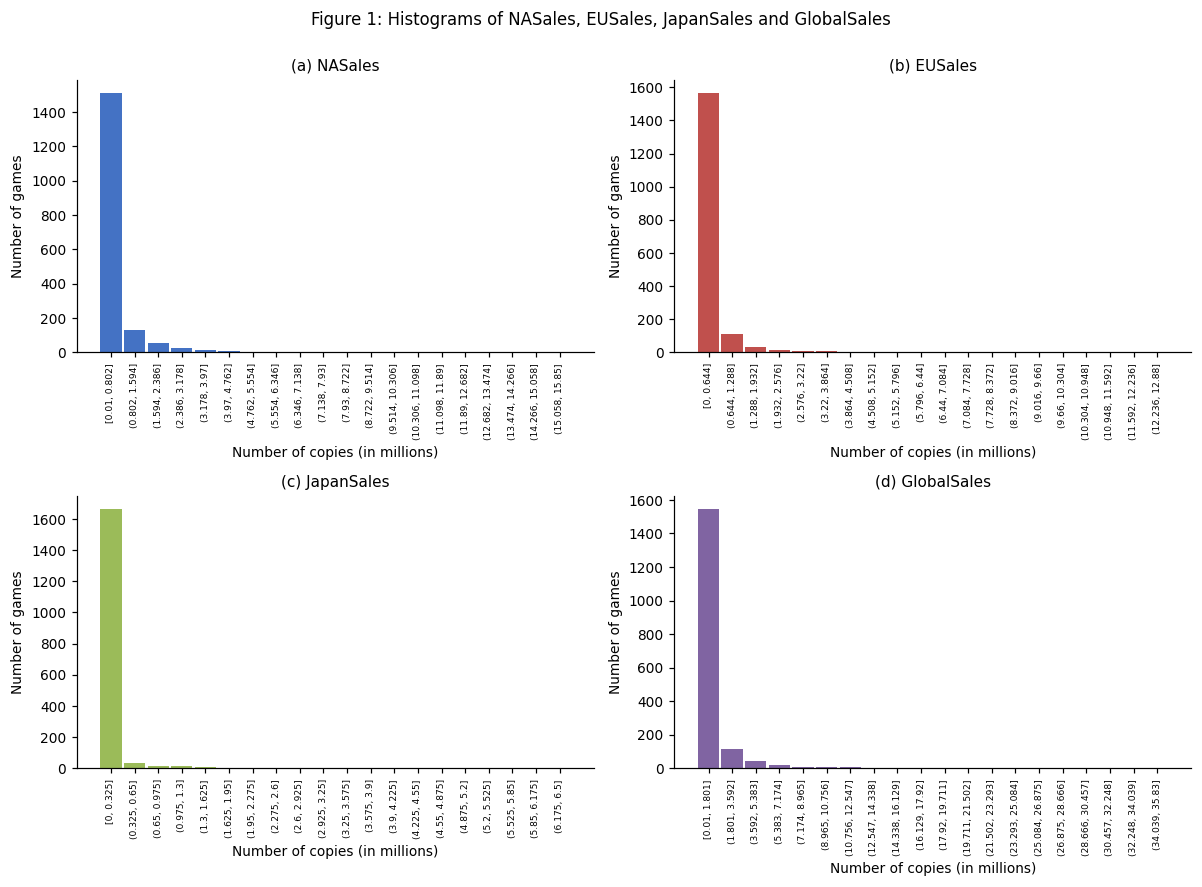

In [17]:
# One colour per variable, used in both figures
COLOURS = {"NASales": "#4472C4", "EUSales": "#C0504D", "JapanSales": "#9BBB59", "GlobalSales": "#8064A2"}
PANELS = ["NASales", "EUSales", "JapanSales", "GlobalSales"]      # order of panels (a) to (d)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col, letter in zip(axes.flatten(), PANELS, "abcd"):
    x = df[col]

    # 20 equal-width bins from the smallest to the largest value
    edges = np.linspace(x.min(), x.max(), 21)
    # pd.cut puts a value in a bin (left edge, right edge]; include_lowest=True also keeps the minimum in the first bin
    bins = pd.cut(x, bins=edges, include_lowest=True)
    counts = bins.value_counts(sort=False)          # number of games in each bin, in order

    ax.bar(range(20), counts.values, width=0.9, color=COLOURS[col])
    ax.set_title(f"({letter}) {col}")
    ax.set_ylabel("Number of games")
    ax.set_xlabel("Number of copies (in millions)")

    # Label each bin with its interval, e.g. [0.01, 0.802] for the first bin and (0.802, 1.594] for the next
    # (:g after rounding to 3 decimals drops trailing zeros, e.g. 0.800 becomes 0.8)
    edge_text = [f"{round(e, 3):g}" for e in edges]
    labels = [f"[{edge_text[0]}, {edge_text[1]}]"] + [f"({edge_text[i]}, {edge_text[i + 1]})".replace(")", "]") for i in range(1, 20)]
    ax.set_xticks(range(20))
    ax.set_xticklabels(labels, rotation=90, fontsize=6)

fig.suptitle("Figure 1: Histograms of NASales, EUSales, JapanSales and GlobalSales", y=1.0)
fig.tight_layout()
plt.show()

**Boxplots (Figure 2).** The box runs from Q1 to Q3 with a line at the median, the cross marks the mean, the whiskers stop at the furthest game within 1.5 x IQR of the box,
and every dot beyond a whisker is an outlier. Panel (a) shows the full range and panel (b) zooms in to 0 to 2.5 so the boxes can be read (outliers above 2.5 are not shown).

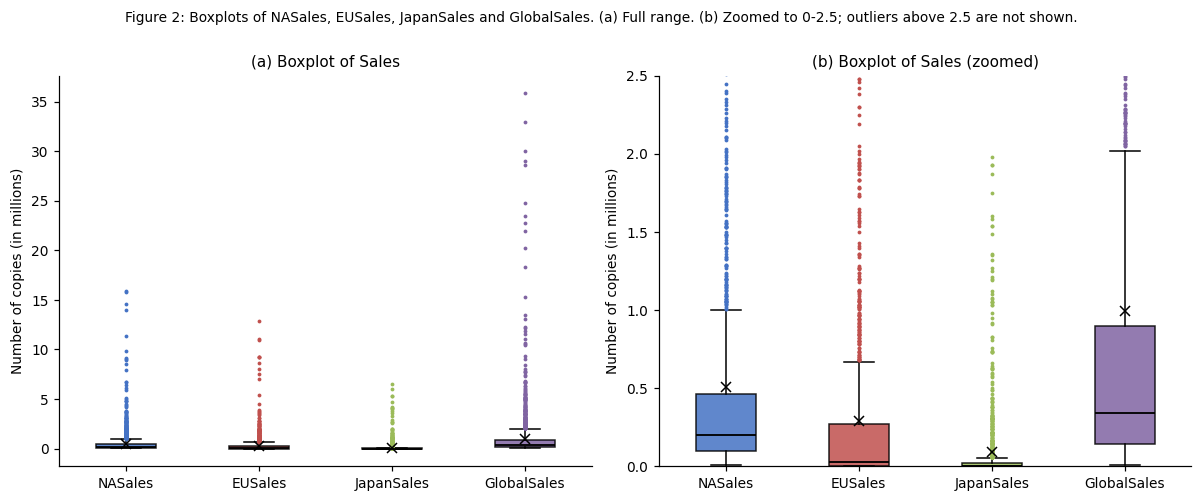

In [18]:
ORDER = ["NASales", "EUSales", "JapanSales", "GlobalSales"]     # order of the boxes, left to right

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, zoom in zip(axes, [False, True]):
    # whis=1.5 draws the whiskers with the 1.5 x IQR rule; showmeans adds a cross at the mean
    bp = ax.boxplot([df[c] for c in ORDER], whis=1.5, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="x", markeredgecolor="black", markersize=6),
                    medianprops=dict(color="black", lw=1.2),
                    flierprops=dict(marker="o", markersize=2.5, markeredgecolor="none"))
    # Colour each box and its outlier dots with the colour of its variable
    for box_patch, flier, col in zip(bp["boxes"], bp["fliers"], ORDER):
        box_patch.set_facecolor(COLOURS[col])
        box_patch.set_alpha(0.85)
        flier.set_markerfacecolor(COLOURS[col])
    ax.set_xticks(range(1, 5))
    ax.set_xticklabels(ORDER)
    ax.set_ylabel("Number of copies (in millions)")
    if zoom:
        ax.set_ylim(0, 2.5)
        ax.set_title("(b) Boxplot of Sales (zoomed)")
    else:
        ax.set_title("(a) Boxplot of Sales")

fig.suptitle("Figure 2: Boxplots of NASales, EUSales, JapanSales and GlobalSales. (a) Full range. (b) Zoomed to 0-2.5; outliers above 2.5 are not shown.", y=1.0, fontsize=9)
fig.tight_layout()
plt.show()

**Table 1: summary statistics.** Mean, standard deviation (n - 1 divisor) and the 5-number summary of each variable, using the course method for quartiles.

In [19]:
# Rebuild the table from the summary computed above, in the order used in the report
table1 = summary.T.loc[["North America", "Europe", "Japan", "Global"],
                       ["Minimum", "Q1", "Median", "Q3", "Maximum", "Mean", "Standard deviation"]]
table1.index = ["NASales", "EUSales", "JapanSales", "GlobalSales"]
table1.round(3)

,Minimum,Q1,Median,Q3,Maximum,Mean,Standard deviation
NASales,0.010,0.100,0.200,0.460,15.850,0.506,1.138
EUSales,0.000,0.000,0.030,0.270,12.880,0.289,0.854
JapanSales,0.000,0.000,0.000,0.020,6.500,0.094,0.448
GlobalSales,0.010,0.140,0.340,0.900,35.830,0.996,2.513


In [20]:
# Extra numbers used in the written discussion of Question 3
g = df["GlobalSales"]
print(f"Proportion of games selling less than 1 million copies globally : {(g < 1).mean():.1%}")
print(f"Best-selling game (global)                                 : {g.max():.2f} million")
print(f"Maximum divided by the median (GlobalSales)                : {g.max() / g.median():.0f} times")
print(f"Standard deviation divided by the mean (GlobalSales)       : {g.std(ddof=1) / g.mean():.2f} times")
print(f"North America mean as a fraction of the global mean        : {df['NASales'].mean() / g.mean():.0%}")
print(f"Games with no sales in Japan                               : {(df['JapanSales'] == 0).mean():.1%}")

print("\nMean compared with Q3 (the mean is above Q3 when a few big hits pull it up):")
for col in PANELS:
    q1, med, q3 = course_quartiles(df[col])
    print(f"  {col:<12} mean {df[col].mean():.3f}  Q3 {q3:.3f}  mean above Q3: {df[col].mean() > q3}")

print("\nProportion of total global sales by region:")
print((df[REGIONS].sum() / g.sum()).round(3).to_string())
print(f"\nProportion of games selling LESS than the global mean ({g.mean():.2f}m): {(g < g.mean()).mean():.1%}")
top10 = g.sort_values(ascending=False).head(round(len(df) * 0.10)).sum() / g.sum()
print(f"Proportion of global sales from the top 10% of games            : {top10:.1%}")

Proportion of games selling less than 1 million copies globally : 77.5%
Best-selling game (global)                                 : 35.83 million
Maximum divided by the median (GlobalSales)                : 105 times
Standard deviation divided by the mean (GlobalSales)       : 2.52 times
North America mean as a fraction of the global mean        : 51%
Games with no sales in Japan                               : 65.6%

Mean compared with Q3 (the mean is above Q3 when a few big hits pull it up):
  NASales      mean 0.506  Q3 0.460  mean above Q3: True
  EUSales      mean 0.289  Q3 0.270  mean above Q3: True
  JapanSales   mean 0.094  Q3 0.020  mean above Q3: True
  GlobalSales  mean 0.996  Q3 0.900  mean above Q3: True

Proportion of total global sales by region:
NASales      0.508
EUSales      0.290
JapanSales   0.094
OtherSales   0.108

Proportion of games selling LESS than the global mean (1.00m): 77.5%
Proportion of global sales from the top 10% of games            : 57.8%


**Reading the results.** All four variables are strongly right-skewed: the mean is larger than the median and the standard deviation
is larger than the mean, because a small number of blockbusters stretch the right tail. The *median* is therefore the better description
of a typical game. Japan is the extreme case, with a median of 0 (most games record no Japanese sales). The 1.5 x IQR rule flags many games as "outliers" (about 10% for North America, Europe and Global, and 289 games for Japan, where the cut-off is only 0.05 million),
because the data are so skewed that even ordinary smaller sellers fall beyond it. The genuinely extreme games, such as Mario Kart Wii at 35.83 million, look real rather than errors,
so they are **kept** (the notes advise against removing outliers unnecessarily).

### Question 4: Metascore labels and consoles

**(a)** Metacritic describes a score as: *Universally acclaimed* (90-100), *Generally favourable* (75-89), *Mixed/average* (50-74),
*Generally unfavourable* (20-49) or *The worst of the worst* (0-19). We convert `ReviewScore` into these five labels and compare the proportion of games with each label.

In [21]:
# The five bands from the project brief. pd.cut puts a score s in a band when lower < s <= upper,
# so the edges below give 0-19, 20-49, 50-74, 75-89 and 90-100 (ReviewScore only takes whole numbers from 12 to 98).
edges = [-1, 19, 49, 74, 89, 100]
labels = ["Worst of the worst (0-19)", "Generally unfavourable (20-49)", "Mixed/average (50-74)",
          "Generally favourable (75-89)", "Universally acclaimed (90-100)"]
df["Metascore"] = pd.cut(df["ReviewScore"], bins=edges, labels=labels)

# Check that every game received a label (no score fell outside the bands)
print("Games without a label:", int(df["Metascore"].isna().sum()))

# Count the games in each band and turn the counts into proportions and percentages
overall = pd.DataFrame({
    "games": df["Metascore"].value_counts().reindex(labels),
    "proportion": df["Metascore"].value_counts(normalize=True).reindex(labels),
})
overall["%"] = overall["proportion"] * 100
print("Total games:", overall["games"].sum())
overall

Games without a label: 0
Total games: 1754


,games,proportion,%
Metascore,,,
Worst of the worst (0-19),4,0.002,0.228
Generally unfavourable (20-49),170,0.097,9.692
Mixed/average (50-74),941,0.536,53.649
Generally favourable (75-89),578,0.330,32.953
Universally acclaimed (90-100),61,0.035,3.478


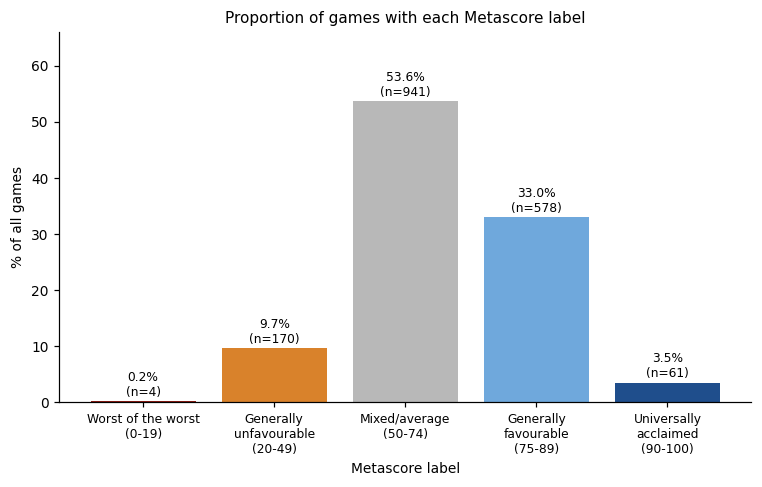

In [22]:
# Colours run from red/orange (low scores) through grey (mixed) to blue (high scores); used in both Question 4 charts
colours = ["#8C1C13", ORANGE, "#B8B8B8", "#6FA8DC", "#1F4E8C"]

# Chart for (a): one bar per Metascore band, labelled with the percentage and the number of games
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(5), overall["%"], color=colours)
ax.set_xticks(range(5))
ax.set_xticklabels(["Worst of the worst\n(0-19)", "Generally\nunfavourable\n(20-49)", "Mixed/average\n(50-74)",
                    "Generally\nfavourable\n(75-89)", "Universally\nacclaimed\n(90-100)"], fontsize=8)
for i, (pct, n) in enumerate(zip(overall["%"], overall["games"])):
    ax.text(i, pct + 1, f"{pct:.1f}%\n(n={n})", ha="center", fontsize=8)
ax.set_ylim(0, 66)
ax.set_ylabel("% of all games")
ax.set_xlabel("Metascore label")
ax.set_title("Proportion of games with each Metascore label")
fig.tight_layout()
plt.show()

**(b)** Compare the proportions of each label *within each console* (row percentages) and show them as a 100% stacked bar chart.

In [23]:
# Count the games in each console x band cell, then divide by each console's total so every row adds up to 100%
counts = pd.crosstab(df["Console"], df["Metascore"]).reindex(columns=labels)
row_pct = counts.div(counts.sum(axis=1), axis=0) * 100
# Extra column: proportion of games scoring 75 or above (favourable + acclaimed), a simple way to compare consoles
row_pct["75+ combined"] = row_pct[labels[3]] + row_pct[labels[4]]
print("Counts:")
display(counts)
print("Row percentages (% of each console's games):")
display(row_pct.round(1))

Counts:


Metascore,Worst of the worst (0-19),Generally unfavourable (20-49),Mixed/average (50-74),Generally favourable (75-89),Universally acclaimed (90-100)
Console,,,,,
Nintendo DS,1,54,237,114,6
Nintendo Wii,2,43,170,68,9
PlayStation 3,1,16,141,132,21
Sony PSP,0,21,185,97,2
X360,0,36,208,167,23


Row percentages (% of each console's games):


Metascore,Worst of the worst (0-19),Generally unfavourable (20-49),Mixed/average (50-74),Generally favourable (75-89),Universally acclaimed (90-100),75+ combined
Console,,,,,,
Nintendo DS,0.200,13.100,57.500,27.700,1.500,29.100
Nintendo Wii,0.700,14.700,58.200,23.300,3.100,26.400
PlayStation 3,0.300,5.100,45.300,42.400,6.800,49.200
Sony PSP,0.000,6.900,60.700,31.800,0.700,32.500
X360,0.000,8.300,47.900,38.500,5.300,43.800


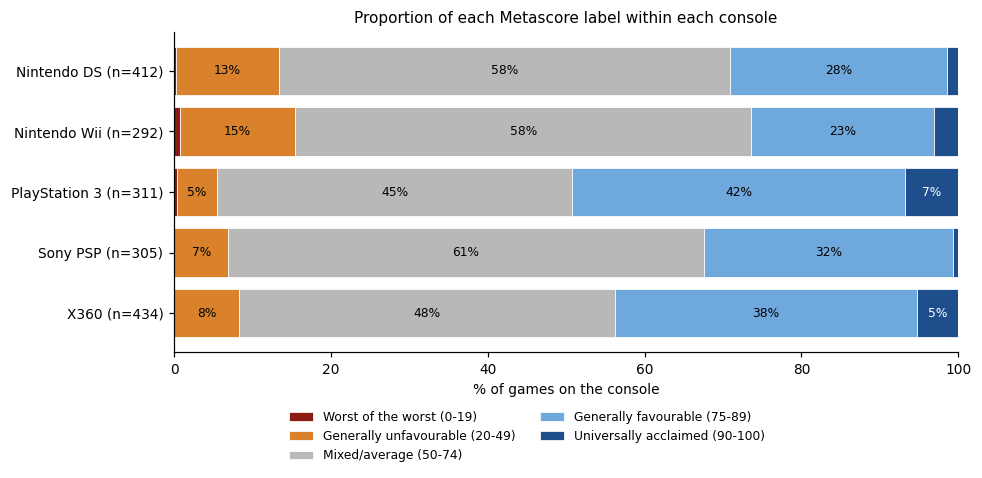

In [24]:
# Chart for (b): 100% stacked horizontal bars, one per console; each segment starts where the previous one ended
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(row_pct))
for label, colour in zip(labels, colours):
    ax.barh(range(len(row_pct)), row_pct[label], left=left, color=colour, label=label, edgecolor="white", lw=0.5)
    # Write the percentage inside segments that are wide enough to hold the text
    for y, (start, width) in enumerate(zip(left, row_pct[label])):
        if width >= 5:
            ax.text(start + width / 2, y, f"{width:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if colour in ("#8C1C13", "#1F4E8C") else "black")
    left += row_pct[label].values
ax.set_yticks(range(len(row_pct)))
ax.set_yticklabels([f"{c} (n={counts.loc[c].sum()})" for c in row_pct.index])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of games on the console")
ax.set_title("Proportion of each Metascore label within each console")
ax.legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.15), frameon=False)
fig.tight_layout()
plt.show()

**Proportion of games scoring 75 or above, by console.** To compare the consoles more directly, this chart shows only the proportion of each console's games that are
*Generally favourable* or *Universally acclaimed* (the two top labels together), with the proportion across all games as a dashed reference line.

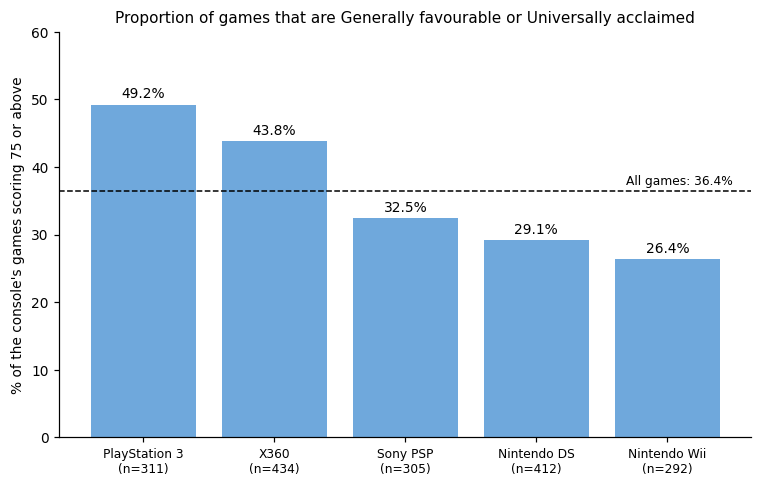

In [25]:
# Proportion of each console's games with a score of 75 or above, sorted from highest to lowest
top_prop = row_pct["75+ combined"].sort_values(ascending=False)
# Proportion across all games, as a reference line (favourable + acclaimed games divided by all games)
overall_top_prop = overall["%"].iloc[3] + overall["%"].iloc[4]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(range(len(top_prop)), top_prop.values, color="#6FA8DC")
for i, v in enumerate(top_prop.values):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.axhline(overall_top_prop, color="black", ls="--", lw=1)
ax.text(len(top_prop) - 0.5, overall_top_prop + 1, f"All games: {overall_top_prop:.1f}%", ha="right", fontsize=8)
ax.set_xticks(range(len(top_prop)))
ax.set_xticklabels([f"{c}\n(n={counts.loc[c].sum()})" for c in top_prop.index], fontsize=8)
ax.set_ylim(0, 60)
ax.set_ylabel("% of the console's games scoring 75 or above")
ax.set_title("Proportion of games that are Generally favourable or Universally acclaimed")
fig.tight_layout()
plt.show()

**Is the rating associated with the console?** The proportions differ across consoles, so from the table and the bar charts the type of console is associated with the type of rating a game receives (from the notes: two variables are associated when the proportions differ).
As a supporting check we run a chi-squared test of association.

- **Null hypothesis:** there is no association between console and rating at the population level.
- **Alternative hypothesis:** there is an association between console and rating at the population level.

If the null hypothesis is true, the number of games we would expect in each cell is (row total x column total) / n. The test compares these expected counts with the observed counts, and the p-value is the probability of
a difference at least this large if the null hypothesis is true. We reject the null hypothesis if the p-value is smaller than the 5% significance level.

The "Worst" band has only 4 games, so the number of games we would expect in it for each console is below 1. This is too small to compare reliably with the observed counts,
so for the test only we merge it with *Generally unfavourable* into one "Below 50" band.

In [26]:
# Expected counts if console and rating were not associated, before merging: (row total x column total) / n
table_full = pd.crosstab(df["Console"], df["Metascore"]).reindex(columns=labels)
expected_full = stats.chi2_contingency(table_full)[3]          # the 4th value returned is the table of expected counts
print(f"Smallest expected count before merging = {expected_full.min():.2f} (the 'Worst' band, which has only {int(table_full[labels[0]].sum())} games)")

# Merge the two lowest bands into "Below 50" (for the test only) and run the chi-squared test of association
merged = df["Metascore"].astype(str).replace({labels[0]: "Below 50", labels[1]: "Below 50"})
table = pd.crosstab(df["Console"], merged)                     # observed counts: console x band
chi2, p, _, expected = stats.chi2_contingency(table)           # chi-squared value, p-value and expected counts
print(f"chi-squared = {chi2:.1f}, p-value = {p:.2e}")
print(f"Smallest expected count after merging = {expected.min():.1f}")

# Observed vs expected games in the "Below 50" band, e.g. for the Nintendo DS and the PlayStation 3
expected_table = pd.DataFrame(expected, index=table.index, columns=table.columns)
for c in ["Nintendo DS", "PlayStation 3"]:
    print(f"{c}, Below 50: expected {expected_table.loc[c, 'Below 50']:.1f}, observed {table.loc[c, 'Below 50']}")

# Decision at the 5% significance level
print("Reject the null hypothesis (association)" if p < 0.05 else "Insufficient evidence to reject the null hypothesis")

Smallest expected count before merging = 0.67 (the 'Worst' band, which has only 4 games)
chi-squared = 85.8, p-value = 3.19e-13
Smallest expected count after merging = 10.2
Nintendo DS, Below 50: expected 40.9, observed 55
PlayStation 3, Below 50: expected 30.9, observed 17
Reject the null hypothesis (association)


**Checking for a confounding variable: licensing.** The association above could be affected by a confounder (from the notes: a variable associated with both of the variables being studied).
Licensed games (games based on an existing brand, film or other property) tend to be rated lower, so we check `Licensed`.
We split each console's games into licensed and not licensed (a bar plot sliced by `Licensed`) and see whether the differences between consoles remain within each group.
If licensing were driving the pattern, the differences would shrink or reverse within each group (as in Simpson's paradox).

Proportion of games scoring 75 or above, by Licensed (0 = not licensed, 1 = licensed):
Licensed
0   41.400
1   27.700

Proportion of each console's games that are licensed (%):
Console
PlayStation 3   43.700
X360            42.900
Nintendo Wii    35.300
Sony PSP        34.800
Nintendo DS     26.000


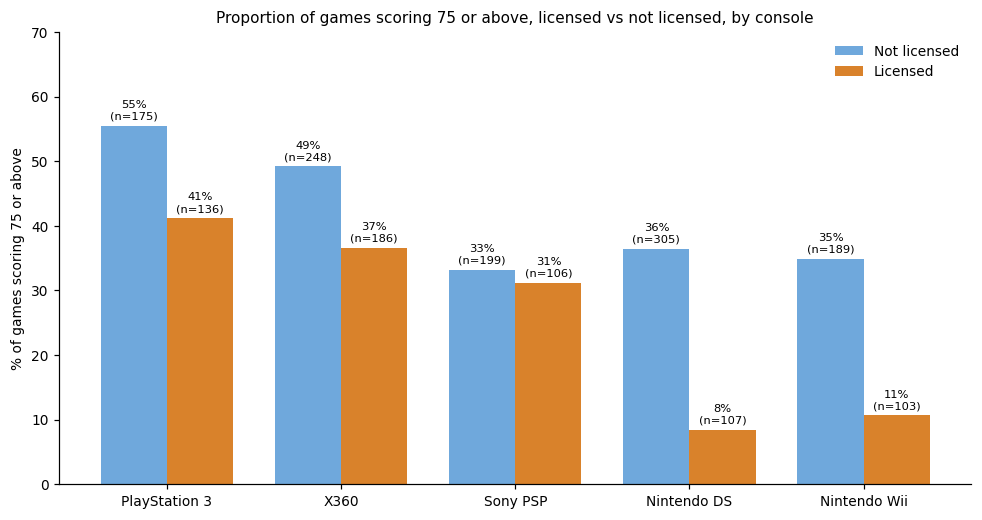

In [27]:
# Is licensing a possible confounder? Proportion scoring 75 or above by Licensed status, and proportion of licensed games on each console
df["Favourable_or_better"] = (df["ReviewScore"] >= 75).astype(int)           # 1 if the score is 75 or above, else 0
print("Proportion of games scoring 75 or above, by Licensed (0 = not licensed, 1 = licensed):")
print((df.groupby("Licensed")["Favourable_or_better"].mean() * 100).round(1).to_string())
print("\nProportion of each console's games that are licensed (%):")
print((df.groupby("Console")["Licensed"].mean() * 100).round(1).sort_values(ascending=False).to_string())

# Proportion of games scoring 75 or above, for each console, separately for licensed and not licensed games
order = row_pct["75+ combined"].sort_values(ascending=False).index           # consoles from highest to lowest overall
by_group = df.groupby(["Console", "Licensed"])["Favourable_or_better"].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(9, 4.8))
width = 0.38
for offset, licensed, colour, name in [(-width / 2, 0, "#6FA8DC", "Not licensed"), (width / 2, 1, ORANGE, "Licensed")]:
    props = [100 * by_group.loc[(c, licensed), "mean"] for c in order]       # percentage of that group's games
    sizes = [by_group.loc[(c, licensed), "count"] for c in order]            # number of games in that group
    bars = ax.bar(np.arange(len(order)) + offset, props, width, color=colour, label=name)
    for x, v, n in zip(np.arange(len(order)) + offset, props, sizes):
        ax.text(x, v + 1, f"{v:.0f}%\n(n={n})", ha="center", fontsize=7.5)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, fontsize=9)
ax.set_ylim(0, 70)
ax.set_ylabel("% of games scoring 75 or above")
ax.set_title("Proportion of games scoring 75 or above, licensed vs not licensed, by console")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Conclusion for (b).** Yes, the type of console is associated with the type of ratings a game receives. The PlayStation 3 and Xbox 360 have higher proportions of
Generally favourable or Universally acclaimed games (49.2% and 43.8%) than the Sony PSP, Nintendo DS and Wii (26.4% to 32.5%), and the chi-squared test agrees (p < 0.001).
The difference persists within both licensed and unlicensed games, so licensing does not fully explain it. This is consistent with the console influencing the ratings, but the data are observational,
so other factors we did not control for (such as genre) may also contribute and we cannot conclude that the console itself causes the difference.

### Question 5: Association between regional sales

**(a) Choosing the independent (x) and dependent (y) variable.** With three regions there are three pairs of regions: North America and Europe, North America and Japan, and Europe and Japan. We fit one line per pair. For each line, the data alone cannot tell us which region's sales should be x. The choice depends on what we want to predict and on information outside the dataset,
such as the order in which a game is released in each region, and whether sales in one region are known before the other. We assume North America (the largest market) is known first, so we use
**North America as x** to predict Europe and Japan, and **Europe as x** to predict Japan. This is an assumption. A regression line shows association, not causation, and the line for predicting x from y is a different line (from the notes).

For each pair we fit a straight line `y = m x + b` and report the correlation coefficient `r`.

In [28]:
PAIRS = [("NASales", "EUSales"), ("NASales", "JapanSales"), ("EUSales", "JapanSales")]


def upper_fence(series):
    # Q3 + 1.5 x IQR, the course rule for a high outlier
    q1, _, q3 = course_quartiles(series)
    return q3 + 1.5 * (q3 - q1)


results = []
for x_col, y_col in PAIRS:
    fit = stats.linregress(df[x_col], df[y_col])                # least-squares line y = m x + b
    predicted = fit.intercept + fit.slope * df[x_col]

    # Same correlation after dropping games that are high outliers in either variable
    keep = (df[x_col] <= upper_fence(df[x_col])) & (df[y_col] <= upper_fence(df[y_col]))
    r_without_outliers = stats.pearsonr(df.loc[keep, x_col], df.loc[keep, y_col])[0]

    results.append({
        "x -> y": f"{x_col} -> {y_col}",
        "slope (m)": fit.slope,
        "intercept (b)": fit.intercept,
        "r": fit.rvalue,
        "r without outliers": r_without_outliers,
        "games kept": int(keep.sum()),
        "predicted y when x = 1 million": fit.intercept + fit.slope * 1,
        "games with a negative prediction": int((predicted < 0).sum()),
    })

regression = pd.DataFrame(results).set_index("x -> y")
display(regression.round(3).T)

# The prediction equation for each pair, written out
for x_col, y_col in PAIRS:
    fit = stats.linregress(df[x_col], df[y_col])
    print(f"{y_col} = {fit.slope:.3f} x {x_col} {fit.intercept:+.3f}")

x -> y,NASales -> EUSales,NASales -> JapanSales,EUSales -> JapanSales
slope (m),0.671,0.254,0.371
intercept (b),-0.050,-0.034,-0.013
r,0.894,0.646,0.709
r without outliers,0.479,0.132,0.193
games kept,"1,519.000","1,374.000","1,387.000"
predicted y when x = 1 million,0.621,0.220,0.358
games with a negative prediction,317.000,643.000,911.000


EUSales = 0.671 x NASales -0.050
JapanSales = 0.254 x NASales -0.034
JapanSales = 0.371 x EUSales -0.013


**Scatter plots with the fitted lines: all games.**

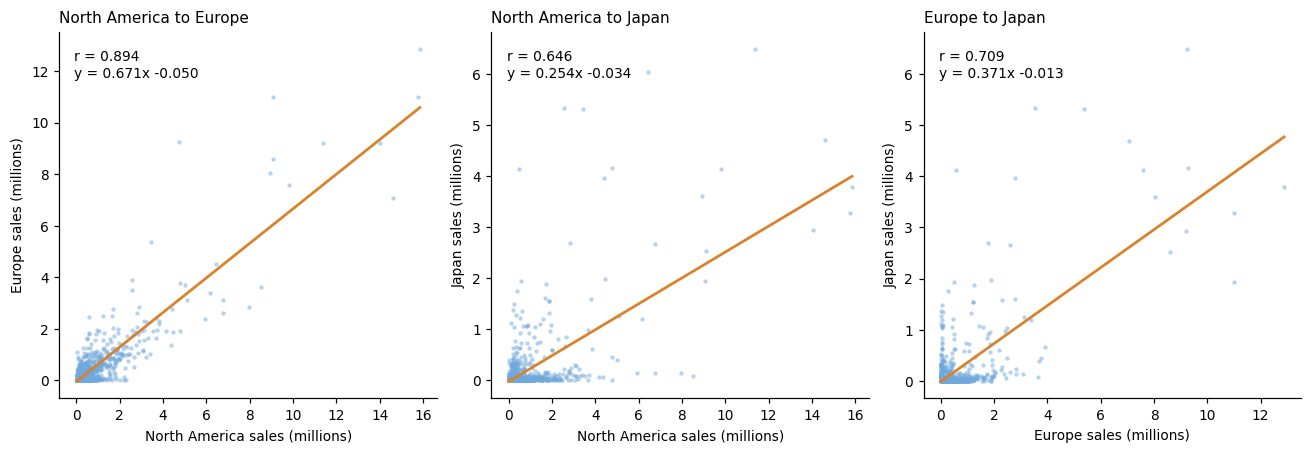

In [29]:
nice = {"NASales": "North America", "EUSales": "Europe", "JapanSales": "Japan"}
POINTS = "#6FA8DC"        # same light blue as the Question 4 charts; the fitted line uses ORANGE as in Question 4

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (x_col, y_col) in zip(axes, PAIRS):
    fit = stats.linregress(df[x_col], df[y_col])
    line_x = np.array([0, df[x_col].max()])                       # draw the line from x = 0 to the largest x
    ax.scatter(df[x_col], df[y_col], s=8, alpha=0.5, color=POINTS, lw=0)
    ax.plot(line_x, fit.intercept + fit.slope * line_x, color=ORANGE, lw=1.8)
    ax.set_xlabel(f"{nice[x_col]} sales (millions)")
    ax.set_ylabel(f"{nice[y_col]} sales (millions)")
    ax.set_title(f"{nice[x_col]} to {nice[y_col]}", loc="left")
    ax.text(0.04, 0.95, f"r = {fit.rvalue:.3f}\ny = {fit.slope:.3f}x {fit.intercept:+.3f}", transform=ax.transAxes, va="top")

fig.tight_layout()
plt.show()

**The same plots zoomed in** on games with both sales below 1.5 million, where most games sit.

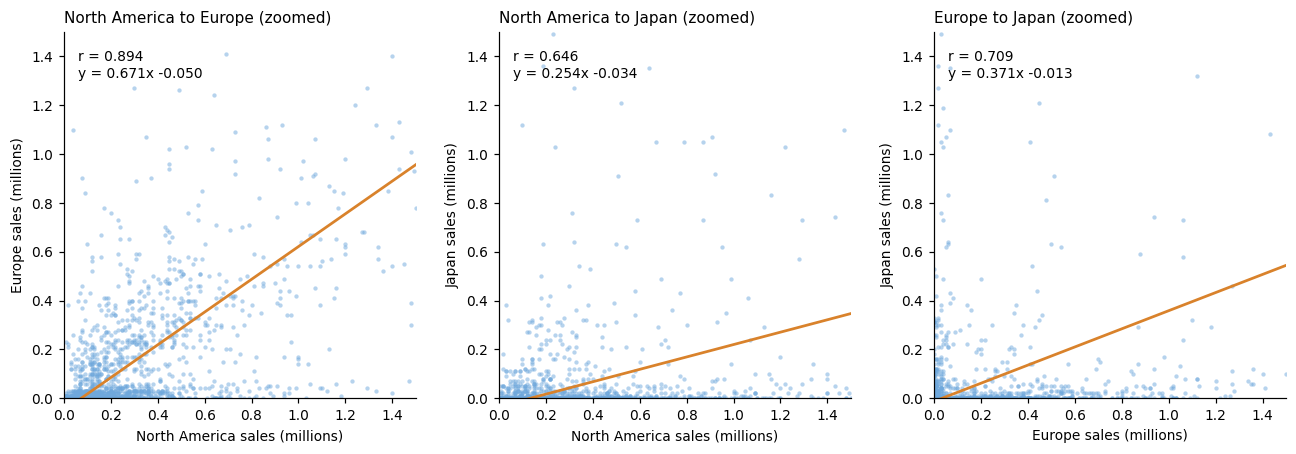

In [30]:
nice = {"NASales": "North America", "EUSales": "Europe", "JapanSales": "Japan"}
POINTS = "#6FA8DC"        # same colours as the other charts

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, (x_col, y_col) in zip(axes, PAIRS):
    fit = stats.linregress(df[x_col], df[y_col])
    line_x = np.array([0, df[x_col].max()])                       # draw the line from x = 0 to the largest x
    ax.scatter(df[x_col], df[y_col], s=8, alpha=0.5, color=POINTS, lw=0)
    ax.plot(line_x, fit.intercept + fit.slope * line_x, color=ORANGE, lw=1.8)
    ax.set_xlabel(f"{nice[x_col]} sales (millions)")
    ax.set_ylabel(f"{nice[y_col]} sales (millions)")
    ax.set_title(f"{nice[x_col]} to {nice[y_col]}", loc="left")
    ax.text(0.04, 0.95, f"r = {fit.rvalue:.3f}\ny = {fit.slope:.3f}x {fit.intercept:+.3f}", transform=ax.transAxes, va="top")
    ax.set_xlim(0, 1.5)                                               # zoom in on games with both sales below 1.5 million
    ax.set_ylim(0, 1.5)
    ax.set_title(f"{nice[x_col]} to {nice[y_col]} (zoomed)", loc="left")
fig.tight_layout()
plt.show()

**Model choice: straight line or non-linear?** The scatter plots do not show an exponential shape, so a straight line is a reasonable first choice. As a check we also try the non-linear route in the notes: fit a line to `ln y` against `x`.
This only works for games with non-zero y (ln 0 is undefined), so the model would drop every game with zero sales in that region (482 games for Europe and 1,150 for Japan). We compare the correlation of the two models on the games that remain.

In [31]:
for x_col, y_col in PAIRS:
    positive = df[df[y_col] > 0]                               # ln(0) is undefined
    r_linear = stats.pearsonr(positive[x_col], positive[y_col])[0]
    r_log = stats.pearsonr(positive[x_col], np.log(positive[y_col]))[0]
    print(f"{x_col:>10} -> {y_col:<10}  games = {len(positive):>4}   "
          f"r (straight line) = {r_linear:.2f}   r (ln y vs x) = {r_log:.2f}")

   NASales -> EUSales     games = 1272   r (straight line) = 0.89   r (ln y vs x) = 0.51
   NASales -> JapanSales  games =  604   r (straight line) = 0.64   r (ln y vs x) = 0.44
   EUSales -> JapanSales  games =  604   r (straight line) = 0.70   r (ln y vs x) = 0.47


In [32]:
# The regression line predicts the average y for a given x. Compare its prediction with the average and the median of the games that actually sold
fit = stats.linregress(df["NASales"], df["EUSales"])
similar = df[(df["NASales"] >= 0.15) & (df["NASales"] <= 0.25)]
print(f"Games with NA sales between 0.15 and 0.25 million: {len(similar)}")
print(f"  the line predicts EU sales of about {fit.intercept + fit.slope * 0.2:.2f} million for NA = 0.2")
print(f"  actual average EU sales for those games: {similar['EUSales'].mean():.2f} million")
print(f"  actual median EU sales for those games: {similar['EUSales'].median():.2f} million")
print(f"  games with zero EU sales among them: {(similar['EUSales'] == 0).sum()}")

# Predicting in the opposite direction gives a different line (from the notes)
reverse = stats.linregress(df["EUSales"], df["NASales"])
print(f"\nPredicting NA from EU instead: NASales = {reverse.slope:.3f} x EUSales {reverse.intercept:+.3f}")
print(f"Slope of the NA -> EU line = {fit.slope:.3f}, so inverting it would give {1 / fit.slope:.3f}, which is not the same line")

Games with NA sales between 0.15 and 0.25 million: 310
  the line predicts EU sales of about 0.08 million for NA = 0.2
  actual average EU sales for those games: 0.09 million
  actual median EU sales for those games: 0.03 million
  games with zero EU sales among them: 70

Predicting NA from EU instead: NASales = 1.192 x EUSales +0.161
Slope of the NA -> EU line = 0.671, so inverting it would give 1.490, which is not the same line


**(b) Suitability for prediction.**

**Purpose.** We use each line to predict one region's sales from another's, for example a game's Japan sales from its North America sales. A suitable model should predict well for most games, so we judge it by the strength of the association and the quality of the data.

**Strength of association.**
- NA -> EU has a strong positive linear association (`r` about 0.89). The two Japan models are moderate (`r` about 0.65 and 0.71). The notes give no cut-offs for strong and moderate, so these labels are our judgement from the size of `r`.
- Removing the games that are high outliers in either variable (13% to 22% of games) makes `r` fall to about 0.48, 0.13 and 0.19. The association comes mostly from games with larger sales.
- The zoomed plots show a wide spread around the lines, and many games sit on the x-axis (decent NA or EU sales but a recorded zero for Japan).
- The lines predict negative sales for many low-selling games (317, 643 and 911 games).
- For games with NA sales near 0.2 million, the line predicts the average EU sales well (0.08 against an actual 0.09 million), but the typical game sells much less (median 0.03 million) because the distribution is skewed.
- The `ln y` against `x` route has lower `r` on the games it can use and drops all games with zero sales, so we keep the straight line.
- Predictions should stay within the range of x in the data.

**Quality of the data.** Sales are rounded to 0.01 million, so a zero means fewer than about 5,000 copies. They are estimates scraped from one website in 2012, games without sales information were removed, and the same title on several consoles appears as separate points, so the observations are not fully independent.

**Conclusion.** Sales in the three regions are positively associated, most strongly between NA and EU. The NA -> EU line is a rough guide to the average sales of games with larger sales. None of the three models is suitable for an individual typical game, and the Japan models are the weakest. The data are observational, so the association does not show that sales in one region influence sales in another.